# Isogeometric layer: evaluate, refine and sample NURBS models (C++)

The C++ counterpart of [`../python/36_iga_refine_evaluate.ipynb`](../python/36_iga_refine_evaluate.ipynb).
A reader of a NURBS file returns the sampled mesh and, through the overloads that take a
`NurbsInfo` (MFEM) or a `BrepInfo` (Kratos CAD JSON, STEP, IGES), the model it was sampled from.
`operations/iga.hpp` acts on that model: `iga_refine` inserts knots and elevates degrees exactly,
`iga_evaluate` returns points, first derivatives, normals and the trimming test, and `iga_sample`
turns a model into Lagrange cells again. See [isogeometric layer](../../doc/iga.md).

In [1]:
#define MESHIOPLUSPLUS_IMPLEMENTATION
#include "../../src/single_include/meshioplusplus/meshioplusplus.hpp"
#include "mio_notebook.hpp"
#include <iostream>
#include <iomanip>
#include <cmath>
using namespace meshioplusplus;
using namespace mio_nb;

// The SVG writer draws linear cells, so a sampled model is drawn through the corners of its
// cells, sampled finely enough that the corners follow the curved geometry.
SvgImage drawCells(const Mesh& cells, double azimuth, double elevation) {
    Mesh linear;
    NDArray points(DType::Float64, {cells.NumPoints(), cells.PointDim()});
    std::copy(cells.Points().As<double>(), cells.Points().As<double>() + points.Size(), points.As<double>());
    linear.AssignPoints(std::move(points));
    for (std::size_t b = 0; b < cells.NumCellBlocks(); ++b) {
        const auto cb = cells.Cells(b);
        const std::string type(cb.Type());
        const bool quad = type.find("QUAD") != std::string::npos || type == "quad9";
        const bool hex = type.find("HEX") != std::string::npos || type == "hexahedron27";
        if (!quad && !hex) continue;
        const std::size_t corners = quad ? 4 : 8;
        NDArray conn(DType::Int64, {cb.NumCells(), corners});
        for (std::size_t c = 0; c < cb.NumCells(); ++c)
            for (std::size_t j = 0; j < corners; ++j)
                conn.As<std::int64_t>()[c * corners + j] = cb.Conn().As<std::int64_t>()[c * cb.NodesPerCell() + j];
        linear.AddCellBlock(quad ? "quad" : "hexahedron", std::move(conn));
    }
    return render(linear, "", "viridis", false, std::nullopt, std::nullopt, azimuth, elevation, 600.0);
}
SvgImage draw(const NurbsInfo& rModel, int perSpan, double azimuth = 35.0, double elevation = 30.0) {
    IgaSampleOptions sampling;
    sampling.mSubdivisions = perSpan;
    return drawCells(iga_sample(rModel, sampling), azimuth, elevation);
}
const std::string NURBS = "../../tests/python/meshes/mfem/nurbs/";
const std::string CAD = "../../tests/python/meshes/cad_json/";

// The models the notebook works on. Each later cell is a function plus its call: a REPL cell
// runs its variable initialisers before its statements, so steps that depend on one another
// are written as statements inside a function, in order.
NurbsInfo disc, hRef, pRef, kRef, pipeInfo, pipeFine;
Mesh discMesh;
BrepInfo roof, plate, plateFine;

## A NURBS surface: refinement changes the net, not the surface

`square-disc-nurbs-patch` is a quadratic rational patch from the MFEM reader's fixtures. The
read returns the sampled cells and a `NurbsInfo`; `iga_refine` then refines every patch.

In [2]:
void readAndRefine() {
    discMesh = read_mfem(NURBS + "square-disc-nurbs-patch.mesh", {}, ReadOptions{}, disc);
    std::cout << "patches: " << disc.mPatches.size() << ", degrees: " << disc.mPatches[0].mDegrees[0] << " x "
              << disc.mPatches[0].mDegrees[1] << ", control points of patch 0: "
              << disc.mPatches[0].mWeights.Size() << "\n";

    IgaRefineOptions h, p, k;
    h.mSubdivisions = {3, 3, 1};
    p.mElevate = {2, 2, 0};
    k.mSubdivisions = {3, 3, 1};
    k.mElevate = {1, 1, 0};
    hRef = iga_refine(disc, h);
    pRef = iga_refine(disc, p);
    kRef = iga_refine(disc, k);
    auto total = [](const NurbsInfo& rInfo) {
        std::size_t n = 0;
        for (const auto& patch : rInfo.mPatches) n += patch.mWeights.Size();
        return n;
    };
    std::cout << "control points: as read " << total(disc) << ", h " << total(hRef) << ", p " << total(pRef)
              << ", k " << total(kRef) << "\n";
}
readAndRefine();

patches: 5, degrees: 2 x 2, control points of patch 0: 12
control points: as read 57, h 185, p 185, k 276


"Exactly" is checkable: evaluate the original and every refined patch at the same parameters,
positions and first derivatives.

In [3]:
void checkExact() {
    const NurbsPatch& p0 = disc.mPatches[0];
    const std::size_t n = 40;
    NDArray uv(DType::Float64, {n * n, 2});
    for (std::size_t j = 0; j < n; ++j)
        for (std::size_t i = 0; i < n; ++i) {
            uv.As<double>()[(j * n + i) * 2] = p0.mKnots[0][2] + (p0.mKnots[0][p0.mKnots[0].size() - 3] - p0.mKnots[0][2]) * i / (n - 1.0);
            uv.As<double>()[(j * n + i) * 2 + 1] = p0.mKnots[1][2] + (p0.mKnots[1][p0.mKnots[1].size() - 3] - p0.mKnots[1][2]) * j / (n - 1.0);
        }
    const IgaEvaluation ref = iga_evaluate(disc, 0, uv, 1);
    const NurbsInfo* models[] = {&hRef, &pRef, &kRef};
    const char* names[] = {"h", "p", "k"};
    for (int m = 0; m < 3; ++m) {
        const IgaEvaluation got = iga_evaluate(*models[m], 0, uv, 1);
        double dx = 0, dd = 0;
        for (std::size_t i = 0; i < ref.mPoints.Size(); ++i)
            dx = std::max(dx, std::abs(ref.mPoints.As<double>()[i] - got.mPoints.As<double>()[i]));
        for (std::size_t i = 0; i < ref.mDerivatives.Size(); ++i)
            dd = std::max(dd, std::abs(ref.mDerivatives.As<double>()[i] - got.mDerivatives.As<double>()[i]));
        std::cout << names[m] << ": max |dx| = " << std::scientific << std::setprecision(2) << dx
                  << "   max |dx/du| = " << dd << "\n";
    }
}
checkExact();

h: max |dx| = 2.66e-15   max |dx/du| = 2.31e-14
p: max |dx| = 4.44e-15   max |dx/du| = 1.60e-14
k: max |dx| = 3.55e-15   max |dx/du| = 3.11e-14


Sampling the refined model draws the same disc: `iga_sample` of a model with its patch topology
is the MFEM reader's own sampling, so only the number of knot-span cells changes (9, then 81).

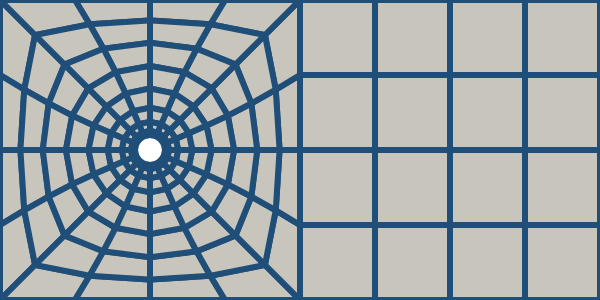

In [4]:
xcpp::display(draw(disc, 4, 0.0, 90.0));

In [5]:
void sampleRefined() {
    NurbsInfo refinedMap;
    const Mesh refinedMesh = iga_sample(kRef, {}, &refinedMap);
    std::cout << "as read: " << discMesh.Cells(0).NumCells() << " cells; k-refined: "
              << refinedMesh.Cells(0).NumCells() << " cells of " << refinedMesh.Cells(0).Type() << "\n";
}
sampleRefined();

as read: 9 cells; k-refined: 81 cells of VTK_LAGRANGE_QUADRILATERAL


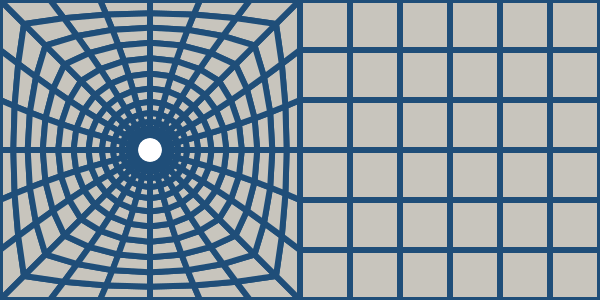

In [6]:
xcpp::display(draw(kRef, 2, 0.0, 90.0));

## Evaluation: derivatives and normals of the Scordelis-Lo roof

A rational patch of degrees (2, 1) from Kratos CAD JSON: an 80° arc of a cylinder of radius 25
about the y axis. The face is evaluated anywhere, with first derivatives and unit normals.

In [7]:
void roofEvaluation() {
    read_cad_json(CAD + "cylindrical_roof.cad.json", roof);
    const NurbsPatch& rp = roof.mPatches[0];
    NDArray ruv(DType::Float64, {9 * 9, 2});
    for (int j = 0; j < 9; ++j)
        for (int i = 0; i < 9; ++i) {
            ruv.As<double>()[(j * 9 + i) * 2] = rp.mKnots[0][2] + (rp.mKnots[0][rp.mKnots[0].size() - 3] - rp.mKnots[0][2]) * i / 8.0;
            ruv.As<double>()[(j * 9 + i) * 2 + 1] = rp.mKnots[1][1] + (rp.mKnots[1][rp.mKnots[1].size() - 2] - rp.mKnots[1][1]) * j / 8.0;
        }
    const IgaEvaluation roofEv = iga_evaluate(roof, 0, ruv, 1);
    double rmin = 1e300, rmax = 0, worst = 1;
    for (std::size_t i = 0; i < roofEv.mPoints.Shape()[0]; ++i) {
        const double* x = roofEv.mPoints.As<double>() + i * 3;
        const double* n = roofEv.mNormals.As<double>() + i * 3;
        const double r = std::hypot(x[0], x[2]);
        rmin = std::min(rmin, r);
        rmax = std::max(rmax, r);
        worst = std::min(worst, std::abs((n[0] * x[0] + n[2] * x[2]) / r));  // normal vs radial direction
    }
    std::cout << std::setprecision(15) << "radius in [" << rmin << ", " << rmax << "], worst |n . r| = " << worst
              << "\n";
}
roofEvaluation();

radius in [2.499999999999999e+01, 2.500000000000000e+01], worst |n . r| = 9.999999999999999e-01


## A trimmed face: the loops stay exact

The plate with a hole is a degree-(2, 2) face bounded by a square loop and a circular hole of four
rational arcs. Refining the face (elevate to degree (3, 4), split every span in three) changes its
net, not its trim: the loops live in the parameter space, which neither refinement moves.
`iga_evaluate` reports for each point whether it is inside the loops.

In [8]:
void plateRefinement() {
    read_cad_json(CAD + "plate_with_hole.cad.json", plate);
    IgaRefineOptions fine;
    fine.mSubdivisions = {3, 3, 1};
    fine.mElevate = {1, 2, 0};
    plateFine = iga_refine(plate, fine);
    std::cout << "degrees " << plate.mPatches[0].mDegrees[0] << "x" << plate.mPatches[0].mDegrees[1] << " -> "
              << plateFine.mPatches[0].mDegrees[0] << "x" << plateFine.mPatches[0].mDegrees[1]
              << ", control points " << plate.mPatches[0].mWeights.Size() << " -> "
              << plateFine.mPatches[0].mWeights.Size() << "\n";

    const std::size_t g = 60;
    NDArray uvGrid(DType::Float64, {g * g, 2});
    for (std::size_t j = 0; j < g; ++j)
        for (std::size_t i = 0; i < g; ++i) {
            uvGrid.As<double>()[(j * g + i) * 2] = 4.0 * i / (g - 1.0);
            uvGrid.As<double>()[(j * g + i) * 2 + 1] = 4.0 * j / (g - 1.0);
        }
    const IgaEvaluation before = iga_evaluate(plate, 0, uvGrid), after = iga_evaluate(plateFine, 0, uvGrid);
    std::size_t inside = 0, differ = 0;
    for (std::size_t i = 0; i < g * g; ++i) {
        inside += before.mInside.As<std::uint8_t>()[i];
        differ += before.mInside.As<std::uint8_t>()[i] != after.mInside.As<std::uint8_t>()[i];
    }
    std::cout << inside << " of " << g * g << " grid points inside the loops; the refined face disagrees at "
              << differ << "\n";
}
plateRefinement();

degrees 2x2 -> 3x4, control points 9 -> 42
2793 of 3600 grid points inside the loops; the refined face disagrees at 0


In [9]:
IgaSampleOptions sampling;
sampling.mSubdivisions = 8;
Mesh plateCells;
void samplePlate() { plateCells = iga_sample(plateFine, sampling); }
samplePlate();

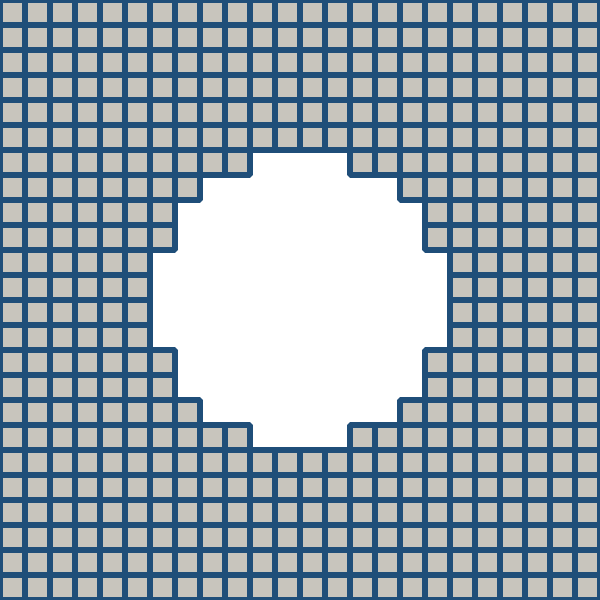

In [10]:
xcpp::display(drawCells(plateCells, 0.0, 90.0));

## Refined models write back

An MFEM model refines every direction alike (its patches share knot vectors along differently
oriented directions) and writes back as an `MFEM NURBS mesh`; a per-direction refinement is refused.

In [11]:
Mesh pipeMesh;
void pipeRoundTrip() {
    read_mfem(NURBS + "pipe-nurbs.mesh", {}, ReadOptions{}, pipeInfo);
    IgaRefineOptions both;
    both.mSubdivisions = {2, 2, 2};
    both.mElevate = {1, 1, 1};
    pipeFine = iga_refine(pipeInfo, both);
    NurbsInfo pipeMapped;
    pipeMesh = iga_sample(pipeFine, {}, &pipeMapped);
    write_mfem("/tmp/meshioplusplus_cpp_nb_pipe_fine.mesh", pipeMesh, false, pipeMapped);
    NurbsInfo back;
    read_mfem("/tmp/meshioplusplus_cpp_nb_pipe_fine.mesh", {}, ReadOptions{}, back);
    std::cout << read_text_file("/tmp/meshioplusplus_cpp_nb_pipe_fine.mesh").substr(0, 20) << "| "
              << back.mPatches.size() << " patches, degree " << back.mPatches[0].mDegrees[0] << "\n";

    IgaRefineOptions uneven;
    uneven.mSubdivisions = {2, 3, 2};
    try {
        iga_refine(pipeInfo, uneven);
    } catch (const std::exception& e) {
        std::cout << "refused: " << e.what() << "\n";
    }
}
pipeRoundTrip();

MFEM NURBS mesh v1.0| 4 patches, degree 3
refused: meshio++: iga: a model with a patch topology refines every direction alike (its patches share knot vectors along differently oriented directions)


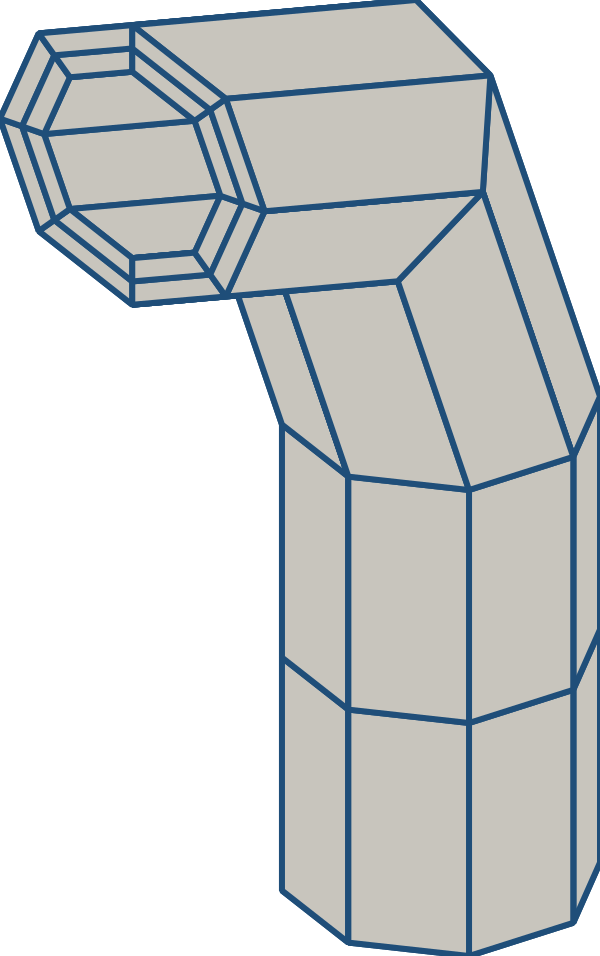

In [12]:
xcpp::display(draw(pipeInfo, 2));

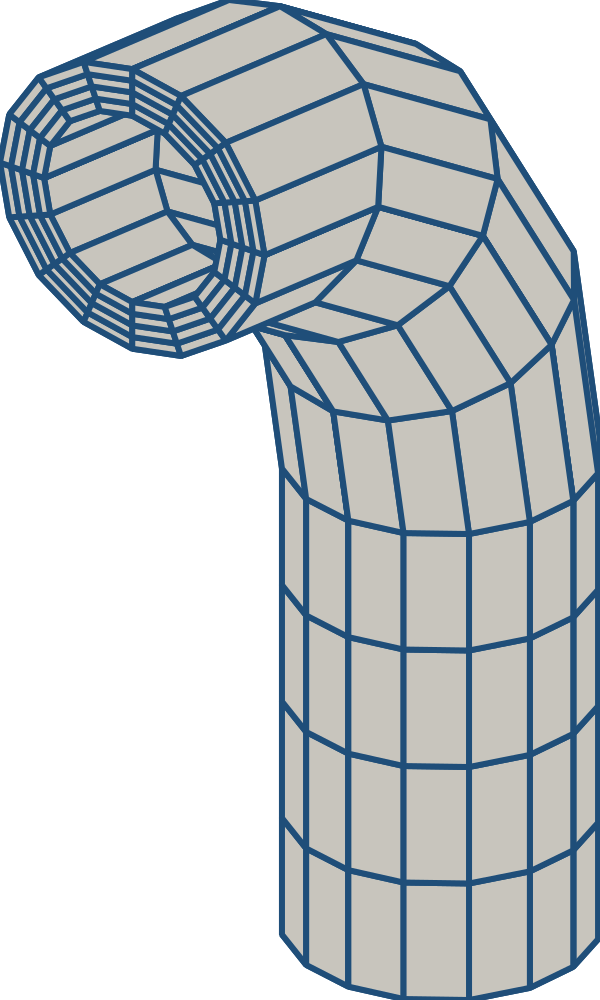

In [13]:
xcpp::display(draw(pipeFine, 2));